# Klasifikasi Tingkat Kesulitan Soal LeetCode

Notebook ini melakukan klasifikasi **single-label** pada target `difficulty`
(Easy, Medium, Hard) dari dataset soal LeetCode. Fitur yang digunakan adalah
embedding fastText (`ftfull_emb_*`, 300 dimensi) yang sudah tersedia pada dataset.

Tiga model dibandingkan: **Logistic Regression**, **Random Forest**, dan **Support Vector Machine (SVM)**.
Setiap model menjalani *hyperparameter tuning* dengan `GridSearchCV` dan validasi silang
stratified 5-fold, lalu dievaluasi pada data uji yang belum pernah dilihat.

## 1. Import dan Konfigurasi

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "sans-serif"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["mathtext.fontset"] = "dejavusans"
plt.rcParams["mathtext.default"] = "regular"
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
sns.set(font="DejaVu Sans")

DATA_PATH = Path("leetcode_classification_ready.csv")
FIGURE_DIR = Path("figures")
RESULT_DIR = Path("results")
FIGURE_DIR.mkdir(exist_ok=True)
RESULT_DIR.mkdir(exist_ok=True)

TARGET = "difficulty"
TEST_SIZE = 0.2
RANDOM_STATE = 42
CV_FOLDS = 5
SCORING = "f1_macro"
DPI = 300

print("Konfigurasi siap.")

Konfigurasi siap.


## 2. Preprocessing

Muat dataset, validasi kolom target dan fitur embedding, lalu buang baris yang
memiliki nilai kosong pada kolom yang dipakai. Hanya kolom `difficulty` yang
digunakan sebagai target (analisis single-label). Pembagian data latih dan uji
dilakukan 80:20 secara stratified agar proporsi kelas tetap terjaga.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset tidak ditemukan: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH)
embedding_columns = [c for c in df.columns if c.startswith("ftfull_emb_")]

if TARGET not in df.columns:
    raise ValueError(f"Kolom target '{TARGET}' tidak ditemukan")
if not embedding_columns:
    raise ValueError("Kolom embedding ftfull_emb_ tidak ditemukan")

df = df.dropna(subset=[TARGET] + embedding_columns).copy()
X = df[embedding_columns].astype("float32")
y = df[TARGET]

print(f"Jumlah data setelah preprocessing: {len(df):,}")
print(f"Jumlah fitur embedding: {len(embedding_columns)}")
print(f"Jumlah kelas: {y.nunique()}")

class_counts = y.value_counts().sort_index()
class_table = class_counts.rename("jumlah").to_frame()
class_table["proporsi (%)"] = (class_table["jumlah"] / len(df) * 100).round(2)
class_table.to_csv(RESULT_DIR / "tabel_distribusi_kelas.csv")
class_table

Jumlah data setelah preprocessing: 3,096
Jumlah fitur embedding: 300
Jumlah kelas: 3


,jumlah,proporsi (%)
difficulty,,
Easy,754,24.35
Hard,739,23.87
Medium,1603,51.78


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Data latih : {X_train.shape[0]:,}")
print(f"Data uji   : {X_test.shape[0]:,}")
print("Distribusi kelas data latih:")
print(y_train.value_counts().sort_index())
print("Distribusi kelas data uji:")
print(y_test.value_counts().sort_index())

Data latih : 2,476
Data uji   : 620
Distribusi kelas data latih:
difficulty
Easy       603
Hard       591
Medium    1282
Name: count, dtype: int64
Distribusi kelas data uji:
difficulty
Easy      151
Hard      148
Medium    321
Name: count, dtype: int64


### 2.1 Visualisasi Distribusi Kelas (Gambar untuk Paper)

Diagram batang jumlah soal per tingkat kesulitan. Ketidakseimbangan kelas
(Medium jauh lebih banyak daripada Easy dan Hard) menjadi konteks penting
untuk pembahasan hasil.

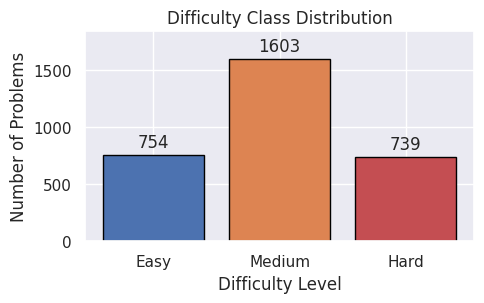

In [4]:
fig, ax = plt.subplots(figsize=(5, 3.2))
order = ["Easy", "Medium", "Hard"]
counts = class_counts.reindex(order)
bars = ax.bar(order, counts.values, color=["#4C72B0", "#DD8452", "#C44E52"], edgecolor="black")
ax.bar_label(bars, fmt="%d", padding=3)
ax.set_xlabel("Difficulty Level")
ax.set_ylabel("Number of Problems")
ax.set_title("Difficulty Class Distribution")
ax.margins(y=0.15)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "fig1_distribusi_kelas.png", dpi=DPI, bbox_inches="tight")
plt.show()

## 3. Definisi Model dan Ruang Hyperparameter

Tiga model digunakan. Logistic Regression dan SVM dibungkus pipeline dengan
`StandardScaler` agar penskalaan hanya dipelajari dari data latih. Setiap model
memiliki ruang parameter yang akan ditelusuri dengan `GridSearchCV`.

| Model | Hyperparameter yang ditelusuri |
|---|---|
| Logistic Regression | `C` |
| Random Forest | `n_estimators`, `max_depth` |
| SVM | `C`, `kernel`, `gamma` |

In [5]:
models_and_grids = {
    "Logistic Regression": (
        make_pipeline(
            StandardScaler(),
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=RANDOM_STATE,
            ),
        ),
        {
            "logisticregression__C": [0.1, 1.0, 10.0],
        },
    ),
    "Random Forest": (
        RandomForestClassifier(
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        {
            "n_estimators": [200, 300, 500],
            "max_depth": [None, 20, 40],
        },
    ),
    "SVM": (
        make_pipeline(
            StandardScaler(),
            SVC(class_weight="balanced", random_state=RANDOM_STATE),
        ),
        {
            "svc__C": [0.1, 1.0, 10.0],
            "svc__kernel": ["linear", "rbf"],
            "svc__gamma": ["scale", "auto"],
        },
    ),
}

for name, (_, grid) in models_and_grids.items():
    n_comb = int(np.prod([len(v) for v in grid.values()]))
    print(f"{name}: {n_comb} kombinasi x {CV_FOLDS} fold")

Logistic Regression: 3 kombinasi x 5 fold
Random Forest: 9 kombinasi x 5 fold
SVM: 12 kombinasi x 5 fold


## 4. Hyperparameter Tuning dengan GridSearchCV

Setiap model dituning menggunakan `StratifiedKFold(5)` dengan metrik `f1_macro`.
Alasan pemilihan F1 macro: memberi bobot yang sama pada setiap kelas sehingga
kelas minoritas (Easy, Hard) tidak terabaikan oleh dominasi kelas Medium.

Seluruh hasil grid disimpan agar dapat dilampirkan pada paper.

In [6]:
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

best_estimators = {}
best_params = {}
cv_results_all = []

for name, (estimator, grid) in models_and_grids.items():
    print(f"Tuning: {name} ...")
    search = GridSearchCV(
        estimator,
        param_grid=grid,
        scoring=SCORING,
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
    )
    search.fit(X_train, y_train)
    best_estimators[name] = search.best_estimator_
    best_params[name] = search.best_params_
    print(f"  Best {SCORING}: {search.best_score_:.4f}")
    print(f"  Best params  : {search.best_params_}")

    tmp = pd.DataFrame(search.cv_results_)
    tmp.insert(0, "model", name)
    tmp = tmp.sort_values("rank_test_score")
    cv_results_all.append(tmp)

cv_results_df = pd.concat(cv_results_all, ignore_index=True)
cv_results_df.to_csv(RESULT_DIR / "tabel_hasil_gridsearch.csv", index=False)

best_params_df = pd.DataFrame(
    [{"model": name, "best_f1_macro_cv": None, "best_params": str(params)}
     for name, params in best_params.items()]
)
print("Ringkasan parameter terbaik:")
for name, params in best_params.items():
    print(f"  {name}: {params}")

Tuning: Logistic Regression ...
  Best f1_macro: 0.4407
  Best params  : {'logisticregression__C': 0.1}
Tuning: Random Forest ...
  Best f1_macro: 0.3324
  Best params  : {'max_depth': 20, 'n_estimators': 300}
Tuning: SVM ...
  Best f1_macro: 0.4730
  Best params  : {'svc__C': 1.0, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}
Ringkasan parameter terbaik:
  Logistic Regression: {'logisticregression__C': 0.1}
  Random Forest: {'max_depth': 20, 'n_estimators': 300}
  SVM: {'svc__C': 1.0, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}


In [7]:
# Simpan ringkasan parameter terbaik beserta skor CV-nya
summary_rows = []
for name in models_and_grids:
    sub = cv_results_df[cv_results_df["model"] == name].iloc[0]
    summary_rows.append(
        {
            "model": name,
            "best_params": str(best_params[name]),
            "f1_macro_cv_mean": round(float(sub["mean_test_score"]), 4),
            "f1_macro_cv_std": round(float(sub["std_test_score"]), 4),
        }
    )
best_summary_df = pd.DataFrame(summary_rows).sort_values("f1_macro_cv_mean", ascending=False)
best_summary_df.to_csv(RESULT_DIR / "tabel_parameter_terbaik.csv", index=False)
best_summary_df

,model,best_params,f1_macro_cv_mean,f1_macro_cv_std
2,SVM,"{'svc__C': 1.0, 'svc__gamma': 'scale', 'svc__k...",0.4730,0.0220
0,Logistic Regression,{'logisticregression__C': 0.1},0.4407,0.0247
1,Random Forest,"{'max_depth': 20, 'n_estimators': 300}",0.3324,0.0074


## 5. Evaluasi pada Data Uji

Model terbaik hasil tuning dievaluasi pada data uji 20%. Metrik yang dihitung:
accuracy, precision macro, recall macro, F1 macro, dan F1 weighted.
Laporan per kelas juga disimpan untuk tiap model.

In [8]:
evaluation_rows = []
classification_reports = {}
fitted_models = {}
predictions_store = {}

for model_name, model in best_estimators.items():
    fitted = clone(model)
    fitted.fit(X_train, y_train)
    predictions = fitted.predict(X_test)
    fitted_models[model_name] = fitted
    predictions_store[model_name] = predictions
    classification_reports[model_name] = classification_report(
        y_test,
        predictions,
        labels=sorted(y.unique()),
        output_dict=True,
        zero_division=0,
    )
    evaluation_rows.append(
        {
            "model": model_name,
            "accuracy": accuracy_score(y_test, predictions),
            "precision_macro": precision_score(y_test, predictions, average="macro", zero_division=0),
            "recall_macro": recall_score(y_test, predictions, average="macro", zero_division=0),
            "f1_macro": f1_score(y_test, predictions, average="macro", zero_division=0),
            "f1_weighted": f1_score(y_test, predictions, average="weighted", zero_division=0),
        }
    )

evaluation_results = pd.DataFrame(evaluation_rows).sort_values("f1_macro", ascending=False).reset_index(drop=True)
evaluation_results.to_csv(RESULT_DIR / "tabel_performa_model.csv", index=False)
evaluation_results

,model,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
0,SVM,0.454839,0.455673,0.481673,0.451651,0.457153
1,Logistic Regression,0.437097,0.433698,0.453704,0.431817,0.441995
2,Random Forest,0.538710,0.528719,0.393054,0.365072,0.452357


In [9]:
# Tabel per kelas untuk setiap model
per_class_rows = []
for model_name, report in classification_reports.items():
    for class_name, scores in report.items():
        if not isinstance(scores, dict) or "f1-score" not in scores:
            continue
        per_class_rows.append(
            {
                "model": model_name,
                "kelas": class_name,
                "precision": round(scores["precision"], 4),
                "recall": round(scores["recall"], 4),
                "f1": round(scores["f1-score"], 4),
                "support": int(scores["support"]),
            }
        )

per_class_df = pd.DataFrame(per_class_rows)
per_class_df.to_csv(RESULT_DIR / "tabel_per_kelas.csv", index=False)

best_model_name = evaluation_results.iloc[0]["model"]
print(f"Model terbaik berdasarkan F1 macro: {best_model_name}")
per_class_df[per_class_df["model"] == best_model_name].reset_index(drop=True)

Model terbaik berdasarkan F1 macro: SVM


,model,kelas,precision,recall,f1,support
0,SVM,Easy,0.4346,0.6159,0.5096,151
1,SVM,Hard,0.3235,0.4459,0.3750,148
2,SVM,Medium,0.6089,0.3832,0.4704,321
3,SVM,macro avg,0.4557,0.4817,0.4517,620
4,SVM,weighted avg,0.4983,0.4548,0.4572,620


## 6. Visualisasi Hasil (Gambar untuk Paper)

Bagian ini menghasilkan gambar-gambar yang akan dilampirkan pada Bab Hasil dan Pembahasan:
perbandingan performa model, confusion matrix model terbaik, metrik per kelas,
dan kurva tuning hyperparameter.

### 6.1 Perbandingan Performa Model (Gambar 2)

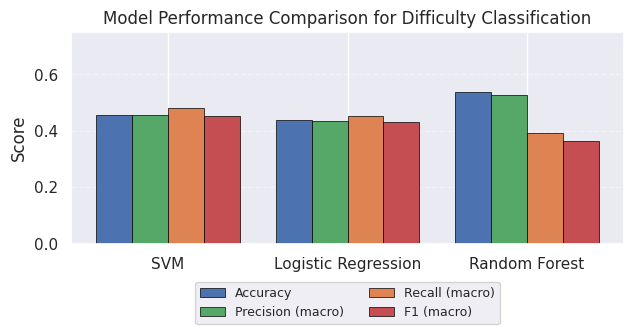

In [10]:
metrics_to_plot = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
metric_labels = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"]
model_order = evaluation_results["model"].tolist()

plot_df = evaluation_results.set_index("model").reindex(model_order)[metrics_to_plot]

x = np.arange(len(model_order))
width = 0.2
fig, ax = plt.subplots(figsize=(6.5, 3.6))
colors = ["#4C72B0", "#55A868", "#DD8452", "#C44E52"]
for i, (metric, label) in enumerate(zip(metrics_to_plot, metric_labels)):
    offset = (i - 1.5) * width
    bars = ax.bar(x + offset, plot_df[metric], width, label=label, color=colors[i], edgecolor="black", linewidth=0.5)

ax.set_xticks(x)
ax.set_xticklabels(model_order)
ax.set_ylabel("Score")
ax.set_ylim(0, 0.75)
ax.set_title("Model Performance Comparison for Difficulty Classification")
ax.legend(ncol=2, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.15))
ax.grid(axis="y", linestyle="--", alpha=0.4)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "fig2_perbandingan_model.png", dpi=DPI, bbox_inches="tight")
plt.show()

### 6.2 Confusion Matrix Model Terbaik (Gambar 3)

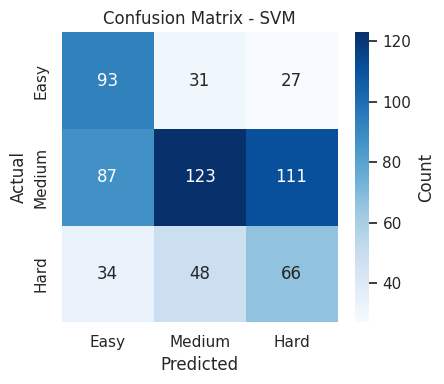

In [11]:
labels_order = ["Easy", "Medium", "Hard"]
cm = confusion_matrix(y_test, predictions_store[best_model_name], labels=labels_order)

fig, ax = plt.subplots(figsize=(4.6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels_order,
    yticklabels=labels_order,
    cbar_kws={"label": "Count"},
    ax=ax,
)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Confusion Matrix - {best_model_name}")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "fig3_confusion_matrix.png", dpi=DPI, bbox_inches="tight")
plt.show()

cm_df = pd.DataFrame(cm, index=[f"aktual_{c}" for c in labels_order], columns=[f"pred_{c}" for c in labels_order])
cm_df.to_csv(RESULT_DIR / "tabel_confusion_matrix.csv")

### 6.3 Metrik per Kelas untuk Model Terbaik (Gambar 4)

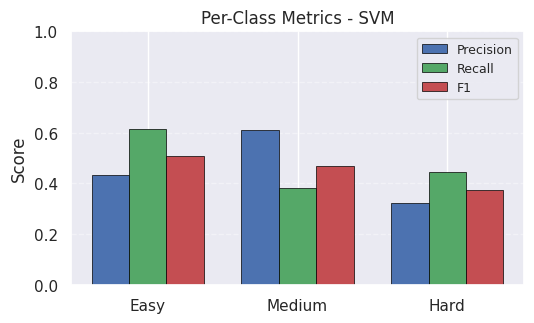

In [12]:
best_per_class = per_class_df[per_class_df["model"] == best_model_name].set_index("kelas").reindex(labels_order)

x = np.arange(len(labels_order))
width = 0.25
fig, ax = plt.subplots(figsize=(5.5, 3.4))
ax.bar(x - width, best_per_class["precision"], width, label="Precision", color="#4C72B0", edgecolor="black", linewidth=0.5)
ax.bar(x, best_per_class["recall"], width, label="Recall", color="#55A868", edgecolor="black", linewidth=0.5)
ax.bar(x + width, best_per_class["f1"], width, label="F1", color="#C44E52", edgecolor="black", linewidth=0.5)
ax.set_xticks(x)
ax.set_xticklabels(labels_order)
ax.set_ylabel("Score")
ax.set_ylim(0, 1.0)
ax.set_title(f"Per-Class Metrics - {best_model_name}")
ax.legend(fontsize=9)
ax.grid(axis="y", linestyle="--", alpha=0.4)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "fig4_metrik_per_kelas.png", dpi=DPI, bbox_inches="tight")
plt.show()

### 6.4 Kurva Hyperparameter Tuning (Gambar 5)

Grafik pengaruh parameter terhadap F1 macro (rata-rata validasi silang).
Berguna untuk menjelaskan mengapa parameter tertentu dipilih.

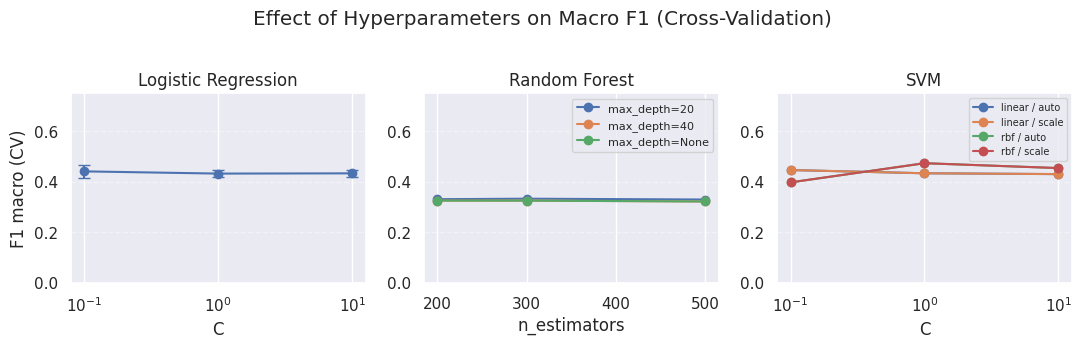

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))

# Logistic Regression: F1 macro vs C
lr = cv_results_df[cv_results_df["model"] == "Logistic Regression"].copy()
lr["C"] = lr["param_logisticregression__C"].astype(float)
lr = lr.sort_values("C")
axes[0].errorbar(lr["C"], lr["mean_test_score"], yerr=lr["std_test_score"], marker="o", capsize=4, color="#4C72B0")
axes[0].set_xscale("log")
axes[0].set_xlabel("C")
axes[0].set_ylabel("F1 macro (CV)")
axes[0].set_title("Logistic Regression")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

# Random Forest: F1 macro vs n_estimators (garis per max_depth)
rf = cv_results_df[cv_results_df["model"] == "Random Forest"].copy()
rf["n_estimators"] = rf["param_n_estimators"].astype(int)
rf["max_depth"] = rf["param_max_depth"].fillna("None").astype(str)
for depth, grp in rf.groupby("max_depth"):
    grp = grp.sort_values("n_estimators")
    axes[1].plot(grp["n_estimators"], grp["mean_test_score"], marker="o", label=f"max_depth={depth}")
axes[1].set_xlabel("n_estimators")
axes[1].set_title("Random Forest")
axes[1].legend(fontsize=8)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

# SVM: F1 macro vs C, garis per kernel/gamma
svm = cv_results_df[cv_results_df["model"] == "SVM"].copy()
svm["C"] = svm["param_svc__C"].astype(float)
svm["combo"] = svm["param_svc__kernel"].astype(str) + " / " + svm["param_svc__gamma"].astype(str)
for combo, grp in svm.groupby("combo"):
    grp = grp.sort_values("C")
    axes[2].plot(grp["C"], grp["mean_test_score"], marker="o", label=combo)
axes[2].set_xscale("log")
axes[2].set_xlabel("C")
axes[2].set_title("SVM")
axes[2].legend(fontsize=7)
axes[2].grid(axis="y", linestyle="--", alpha=0.4)

axes[0].set_ylim(0, 0.75)
axes[1].set_ylim(0, 0.75)
axes[2].set_ylim(0, 0.75)
fig.suptitle("Effect of Hyperparameters on Macro F1 (Cross-Validation)", y=1.02)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "fig5_kurva_tuning.png", dpi=DPI, bbox_inches="tight")
plt.show()

### 6.5 Diagram Alur Penelitian (Gambar 1)

Skema alur eksperimen dari dataset hingga evaluasi. Digambar secara programatik
agar konsisten dengan metodologi pada paper.

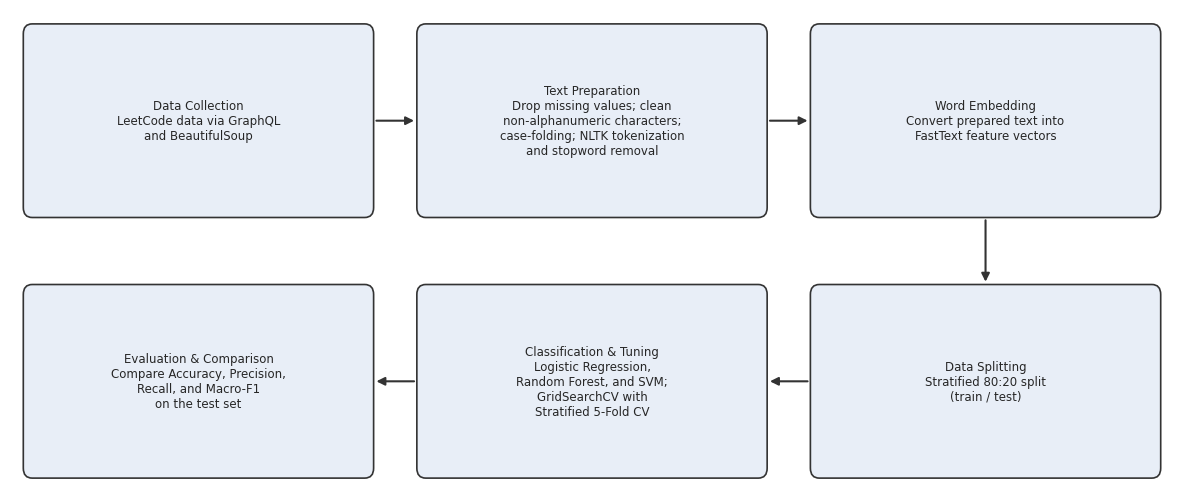

In [ ]:
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(14, 3.2))
ax.axis("off")

steps = [
    "Data Collection\nLeetCode data via GraphQL\nand BeautifulSoup",
    
    "Text Preparation\nDrop missing values; clean\nnon-alphanumeric characters;\ncase-folding; NLTK tokenization\nand stopword removal",
    
    "Word Embedding\nConvert prepared text into\nFastText feature vectors",
    
    "Data Splitting\nStratified 80:20 split\n(train / test)",
    
    "Classification & Tuning\nLogistic Regression,\nRandom Forest, and SVM;\nGridSearchCV with\nStratified 5-Fold CV",
    
    "Evaluation & Comparison\nCompare Accuracy, Precision,\nRecall, and Macro-F1\non the test set",
]

box_w, box_h = 3.0, 1.4
gap = 0.55
x0 = 0.2
y_bottom = 0.35
y_top = 2.45
x_step = box_w + gap

# Posisi mengikuti alur: baris atas 1-2-3, baris bawah 6-5-4
positions = [
    (x0, y_top),                  # 1
    (x0 + x_step, y_top),         # 2
    (x0 + 2 * x_step, y_top),     # 3
    (x0 + 2 * x_step, y_bottom),  # 4
    (x0 + x_step, y_bottom),      # 5
    (x0, y_bottom),               # 6
]

for (x, y), step in zip(positions, steps):
    rect = patches.FancyBboxPatch(
        (x, y),
        box_w,
        box_h,
        boxstyle="round,pad=0.08",
        linewidth=1.2,
        edgecolor="#333333",
        facecolor="#E8EEF7",
    )
    ax.add_patch(rect)
    ax.text(
        x + box_w / 2,
        y + box_h / 2,
        step,
        ha="center",
        va="center",
        fontsize=8.5,
    )

for i in range(len(positions) - 1):
    x1, y1 = positions[i]
    x2, y2 = positions[i + 1]

    if y1 == y2:
        if x2 > x1:  # Panah ke kanan
            start = (x1 + box_w + 0.08, y1 + box_h / 2)
            end = (x2 - 0.08, y2 + box_h / 2)
        else:  # Panah ke kiri
            start = (x1 - 0.08, y1 + box_h / 2)
            end = (x2 + box_w + 0.08, y2 + box_h / 2)
    else:  # Panah turun dari kotak 3 ke kotak 4
        start = (x1 + box_w / 2, y1 - 0.08)
        end = (x2 + box_w / 2, y2 + box_h + 0.08)

    ax.annotate(
        "",
        xy=end,
        xytext=start,
        arrowprops=dict(arrowstyle="-|>", color="#333333", lw=1.5),
    )

ax.set_xlim(x0 - 0.2, x0 + 2 * x_step + box_w + 0.2)
ax.set_ylim(y_bottom - 0.2, y_top + box_h + 0.2)
fig, ax = ax.figure, ax
fig.set_size_inches(12, 5.2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "fig1_alur_penelitian.png", dpi=DPI, bbox_inches="tight")
plt.show()

In [15]:
print("Model terbaik:", best_model_name)
print()
print("Tabel performa akhir:")
display(evaluation_results)
print()
print("Parameter terbaik:")
for name, params in best_params.items():
    print(f"  {name}: {params}")

Model terbaik: SVM

Tabel performa akhir:


,model,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
0,SVM,0.454839,0.455673,0.481673,0.451651,0.457153
1,Logistic Regression,0.437097,0.433698,0.453704,0.431817,0.441995
2,Random Forest,0.538710,0.528719,0.393054,0.365072,0.452357



Parameter terbaik:
  Logistic Regression: {'logisticregression__C': 0.1}
  Random Forest: {'max_depth': 20, 'n_estimators': 300}
  SVM: {'svc__C': 1.0, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}
